In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv("/content/Crop_recommendation_dataset.csv")
df

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
...,...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee


In [3]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [4]:
df.tail()

,N,P,K,temperature,humidity,ph,rainfall,label
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee
2199,104,18,30,23.603016,60.396475,6.779833,140.937041,coffee


In [5]:
df.isnull().sum()

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0


In [6]:
df['label'].unique()

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'grapes', 'watermelon', 'muskmelon', 'apple',
       'orange', 'papaya', 'coconut', 'cotton', 'jute', 'coffee'],
      dtype=object)

In [8]:
# df.columns
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns.tolist()

['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

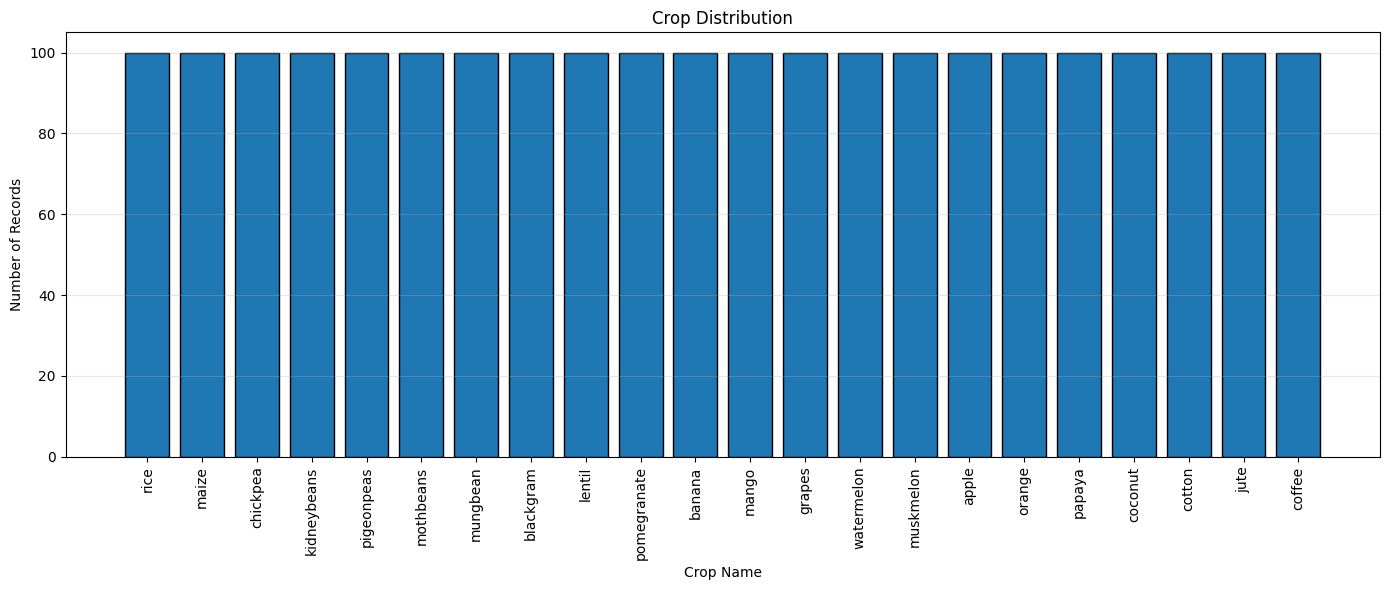

In [13]:
plt.figure(figsize=(14,6))

crop_counts=df['label'].value_counts().sort_values(ascending=False)

plt.bar(crop_counts.index,crop_counts.values,edgecolor='black')

plt.title("Crop Distribution")

plt.xlabel("Crop Name")

plt.ylabel("Number of Records")

plt.xticks(rotation=90)

plt.grid(axis='y',alpha=0.3)

plt.tight_layout()

plt.show()


# If the bars have similar heights, the dataset has a relatively
#  balanced number of samples per crop. Large differences may indicate class imbalance.

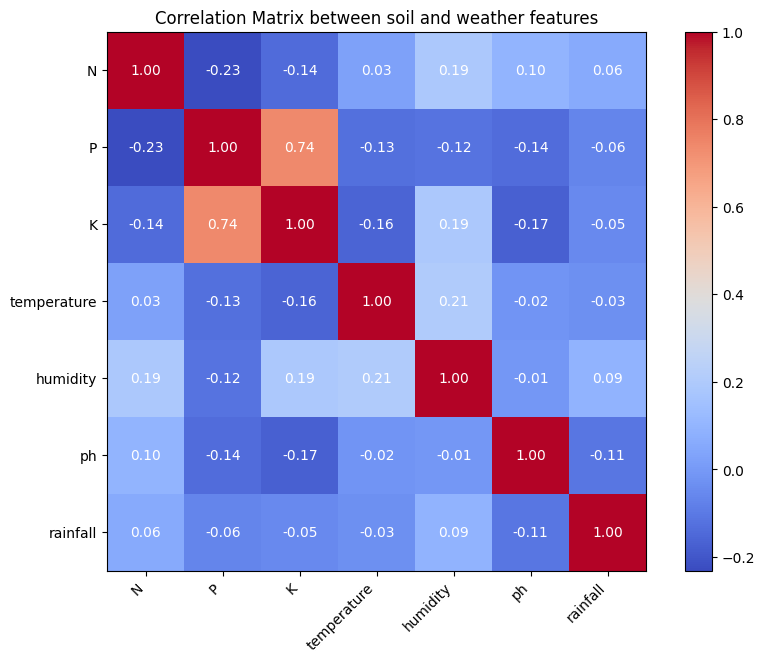

In [14]:
features=['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
correlation=df[features].corr()
plt.figure(figsize=(10,7))

image=plt.imshow(correlation,cmap='coolwarm')

plt.colorbar(image)
plt.xticks(range(len(features)),features,rotation=45,ha='right')
plt.yticks(range(len(features)),features)

for i in range(len(features)):
  for j in range(len(features)):
    plt.text(j,i,f'{correlation.iloc[i,j]:.2f}',ha='center',va='center',color='white')

plt.title("Correlation Matrix between soil and weather features")
plt.show()

In [15]:
# Near +1: strong positive linear relationship.
# Near -1: strong negative linear relationship.
# Near 0: weak linear relationship.
# Remember, correlation does not establish causation, and
# a low correlation does not mean a feature is useless for classification.

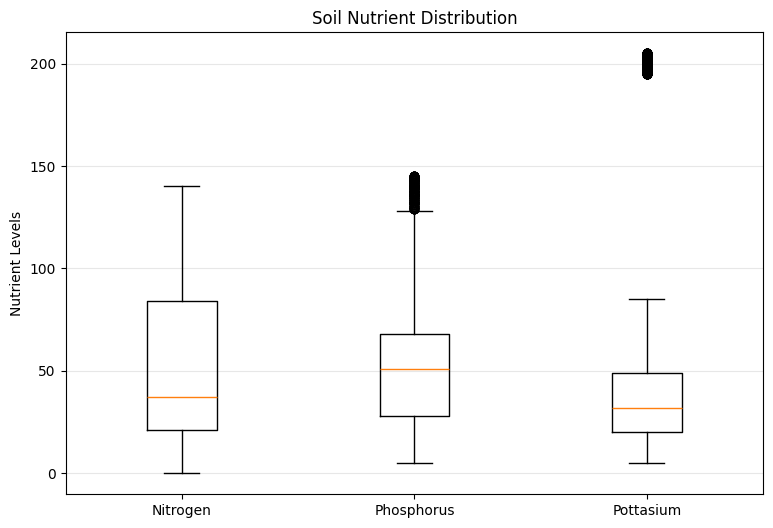

In [16]:
# soil nutrient distribution

plt.figure(figsize=(9,6))

plt.boxplot([df['N'],df['P'],df['K']],tick_labels=['Nitrogen','Phosphorus','Pottasium'])

plt.title("Soil Nutrient Distribution")

plt.ylabel("Nutrient Levels")

plt.grid(axis='y',alpha=0.3)

plt.show()


In [17]:
# The central line represents the median,
# the box represents the middle 50% of values, and
# the points beyond the whiskers may indicate potential outliers.

In [18]:

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Prepare data
data = df[features + ["label"]].copy()

for col in features:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(subset=features + ["label"])
data = data.drop_duplicates().reset_index(drop=True)

X = data[features]
y = data["label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train the Decision Tree
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Model training completed!")


Training samples: 1760
Testing samples: 440
Model training completed!


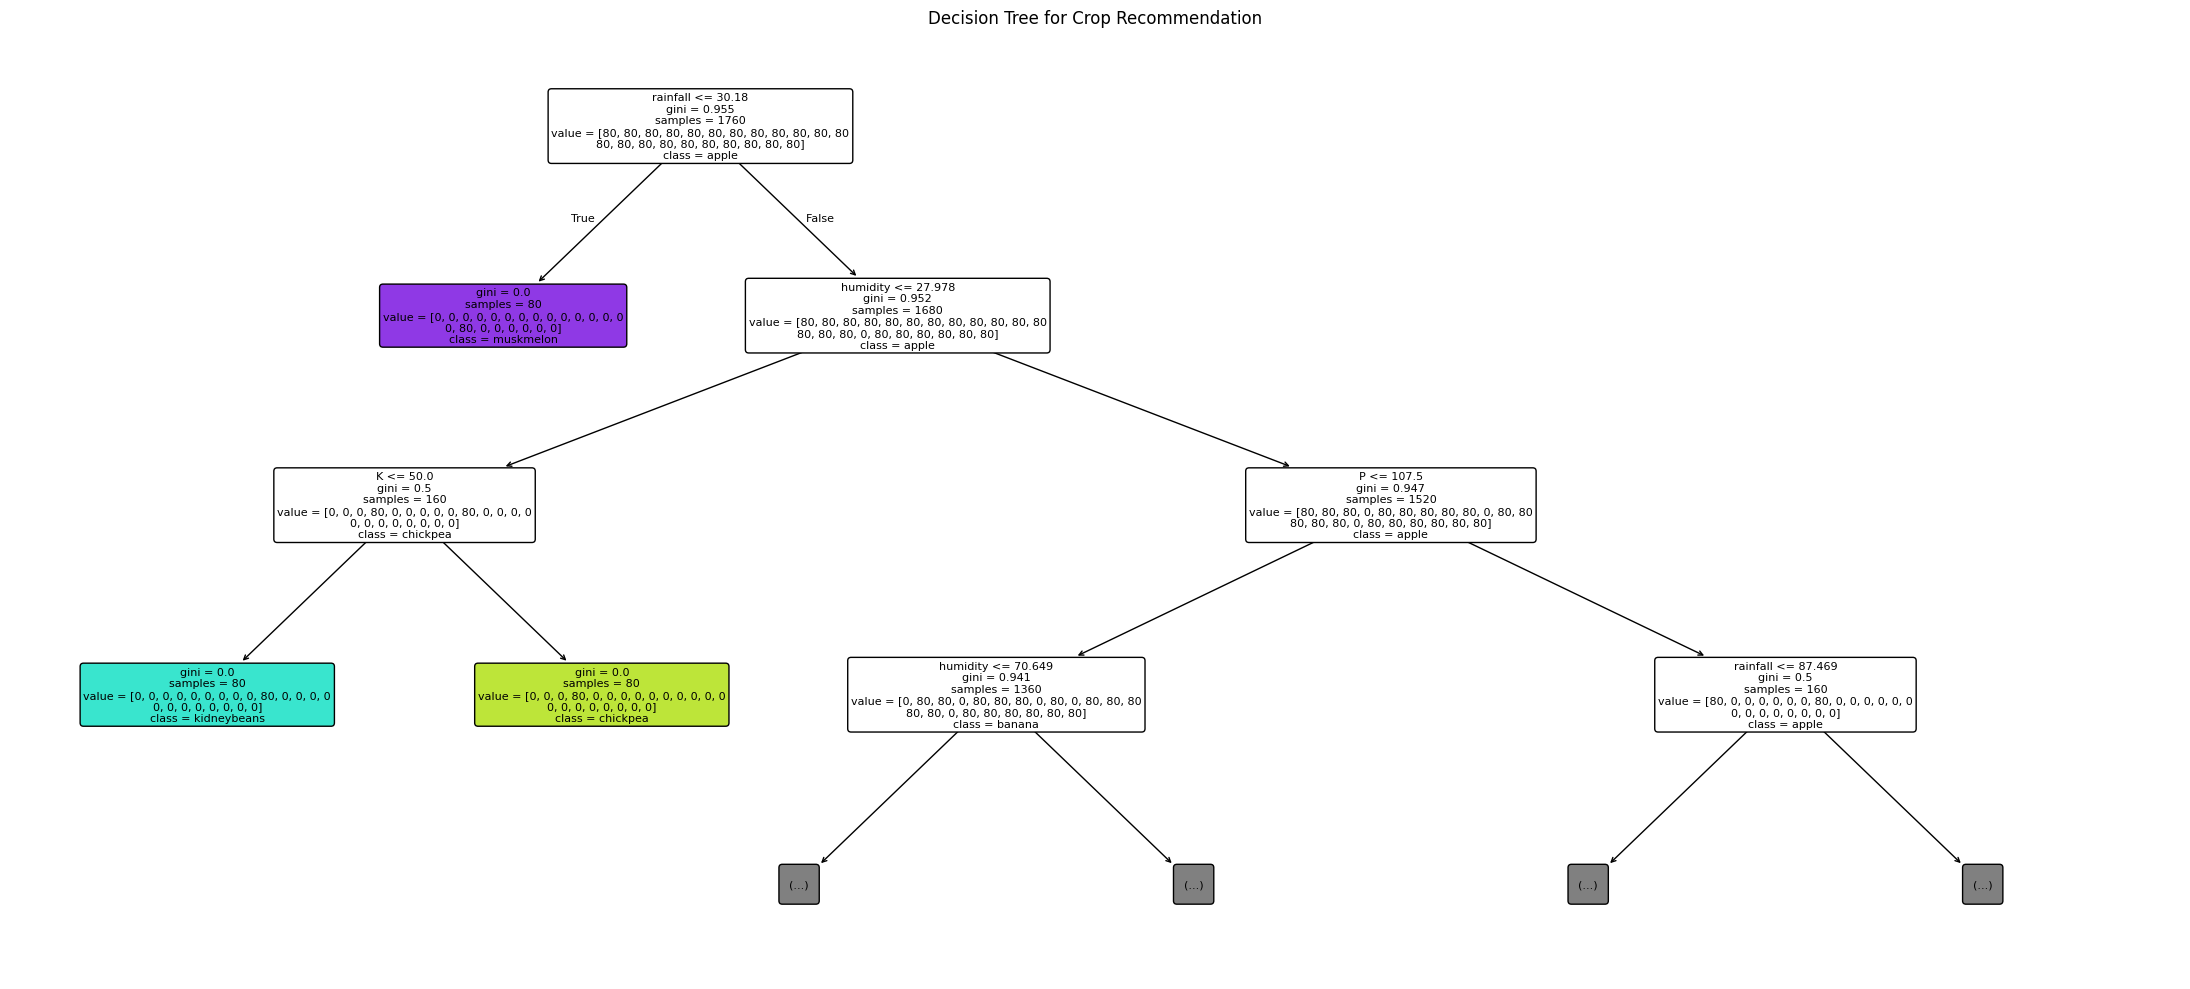

In [19]:

from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))

plot_tree(
    model,
    feature_names=features,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree for Crop Recommendation")
plt.tight_layout()
plt.show()


In [20]:

from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Test Accuracy: 40.68%

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       0.16      1.00      0.27        20
   blackgram       0.19      0.95      0.32        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.25      1.00      0.40        20
      coffee       0.61      1.00      0.75        20
      cotton       0.00      0.00      0.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.00      0.00      0.00        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.00      0.00      0.00        20
       maize       0.00      0.00      0.00        20
       mango       0.00      0.00      0.00        20
   mothbeans       0.00      0.00      0.00        20
    mungbean       0.00      0.00      0.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       0.00      0.00  

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


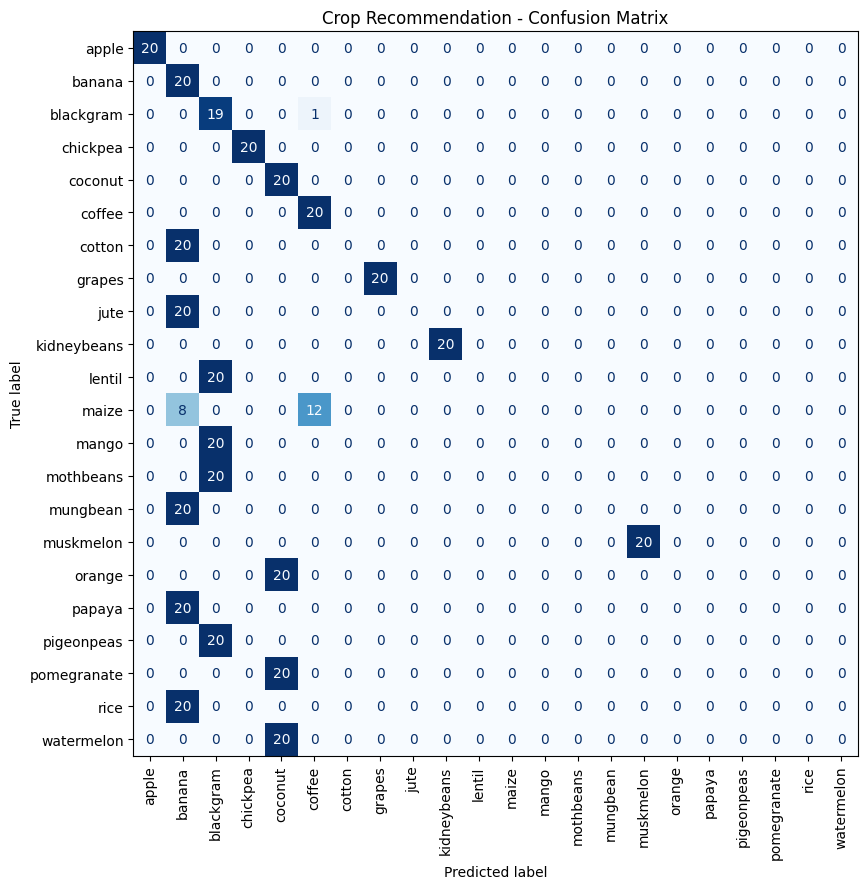

In [21]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(11, 9))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model.classes_,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("Crop Recommendation - Confusion Matrix")
plt.tight_layout()
plt.show()


In [22]:
# Get input from the user
N = float(input("Enter Nitrogen (N): "))
P = float(input("Enter Phosphorus (P): "))
K = float(input("Enter Potassium (K): "))
temperature = float(input("Enter Temperature: "))
humidity = float(input("Enter Humidity: "))
ph = float(input("Enter Soil pH: "))
rainfall = float(input("Enter Rainfall: "))

# Prepare input data
new_sample = pd.DataFrame([{
    "N": N,
    "P": P,
    "K": K,
    "temperature": temperature,
    "humidity": humidity,
    "ph": ph,
    "rainfall": rainfall
}])[features]

# Predict the crop
prediction = model.predict(new_sample)[0]

# Print the result
print("\nRecommended Crop:", prediction)

Enter Nitrogen (N): 90
Enter Phosphorus (P): 42
Enter Potassium (K): 43
Enter Temperature: 22.5
Enter Humidity: 80
Enter Soil pH: 6.5
Enter Rainfall: 200

Recommended Crop: banana
